In [15]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import matplotlib.pyplot as plt

In [16]:
np.random.seed(42)

CITIES = 500
TEST_SIZE = 0.2
RANDOM_STATE = 42

In [17]:
dataset = pd.DataFrame({
    "renda_media": np.random.uniform(800, 5000, CITIES),
    "taxa_alfabetizacao": np.random.uniform(60, 100, CITIES),
    "urbanizacao": np.random.uniform(30, 100, CITIES),
    "escolas_por_10mil": np.random.uniform(1, 10, CITIES),
    "alunos_por_docente": np.random.uniform(10, 35, CITIES),
    "escolas_com_internet": np.random.uniform(10, 100, CITIES)
})

dataset["IDEB"] = (
    1.0
    + dataset["renda_media"] * 0.0003
    + dataset["taxa_alfabetizacao"] * 0.025
    + dataset["urbanizacao"] * 0.008
    + dataset["escolas_por_10mil"] * 0.08
    - dataset["alunos_por_docente"] * 0.025
    + dataset["escolas_com_internet"] * 0.008
    + np.random.normal(0, 0.3, CITIES)
)

dataset["IDEB"] = dataset["IDEB"].clip(0, 10)

In [18]:
dataset.head()
dataset.describe()

,renda_media,taxa_alfabetizacao,urbanizacao,escolas_por_10mil,alunos_por_docente,escolas_com_internet,IDEB
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000
mean,2893.959191,79.278056,66.229069,5.468288,22.496090,55.447106,4.706369
std,1254.491315,11.419738,20.803505,2.583089,7.145229,26.615097,0.672444
min,821.258652,60.185281,30.345799,1.028964,10.039128,10.001047,2.616515
25%,1813.374702,69.163970,46.885963,3.169668,16.702805,33.383276,4.242701
50%,2955.287743,78.872863,67.781684,5.580022,22.400312,55.166870,4.686218
75%,3975.724502,89.053473,84.414063,7.636386,28.582334,79.111578,5.167366
max,4970.452144,99.988707,99.958961,9.985128,34.885938,99.803877,6.643388


In [19]:
X = dataset.drop(columns=["IDEB"])
Y = dataset["IDEB"]

xTrain, xTest, yTrain, yTest = train_test_split(X, Y, test_size=TEST_SIZE, random_state=RANDOM_STATE)

In [20]:
model = LinearRegression()

model.fit(xTrain, yTrain)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](6,)","[ 0. , 0.02, 0.01, 0.08,-0.03, 0.01]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](6,)","['renda_media','taxa_alfabetizacao','urbanizacao','escolas_por_10mil', 'alunos_por_docente','escolas_com_internet']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,1.105
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,6
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(6)


In [21]:
yTrainPred = model.predict(xTrain)
yTestPred = model.predict(xTest)

In [22]:
def Evaluate(yReal, yPred, name):
    mse = mean_squared_error(yReal, yPred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(yReal, yPred)
    r2 = r2_score(yReal, yPred)

    print(f"\n{name}:\n")
    print(f"MSE:  {mse:.4f}")
    print(f"RMSE: {rmse:.4f}")
    print(f"MAE:  {mae:.4f}")
    print(f"R²:   {r2:.4f}")


Evaluate(yTrain, yTrainPred, "TREINAMENTO")
Evaluate(yTest, yTestPred, "TESTE")


TREINAMENTO:

MSE:  0.0838
RMSE: 0.2894
MAE:  0.2350
R²:   0.8210

TESTE:

MSE:  0.0912
RMSE: 0.3020
MAE:  0.2438
R²:   0.7626


In [26]:
print("Weights:\n")
for feature, weight in zip(X.columns, model.coef_):
    print(f"{feature}: {weight:.4f}")

print(f"\nBias: {model.intercept_:.4f}")

Weights:

renda_media: 0.0003
taxa_alfabetizacao: 0.0237
urbanizacao: 0.0080
escolas_por_10mil: 0.0825
alunos_por_docente: -0.0260
escolas_com_internet: 0.0080

Bias: 1.1052


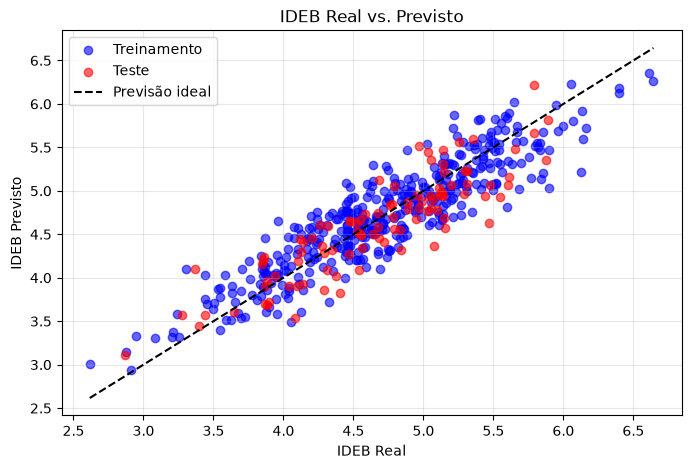

In [27]:
plt.figure(figsize=(8, 5))

plt.scatter(yTrain, yTrainPred, color="blue", alpha=0.6, label="Treinamento")
plt.scatter(yTest, yTestPred, color="red", alpha=0.6, label="Teste")

# Linha de previsão perfeita
minValue = min(Y.min(), yTrainPred.min(), yTestPred.min())
maxValue = max(Y.max(), yTrainPred.max(), yTestPred.max())

plt.plot(
    [minValue, maxValue],
    [minValue, maxValue],
    color="black",
    linestyle="--",
    label="Previsão ideal"
)

plt.xlabel("IDEB Real")
plt.ylabel("IDEB Previsto")
plt.title("IDEB Real vs. Previsto")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

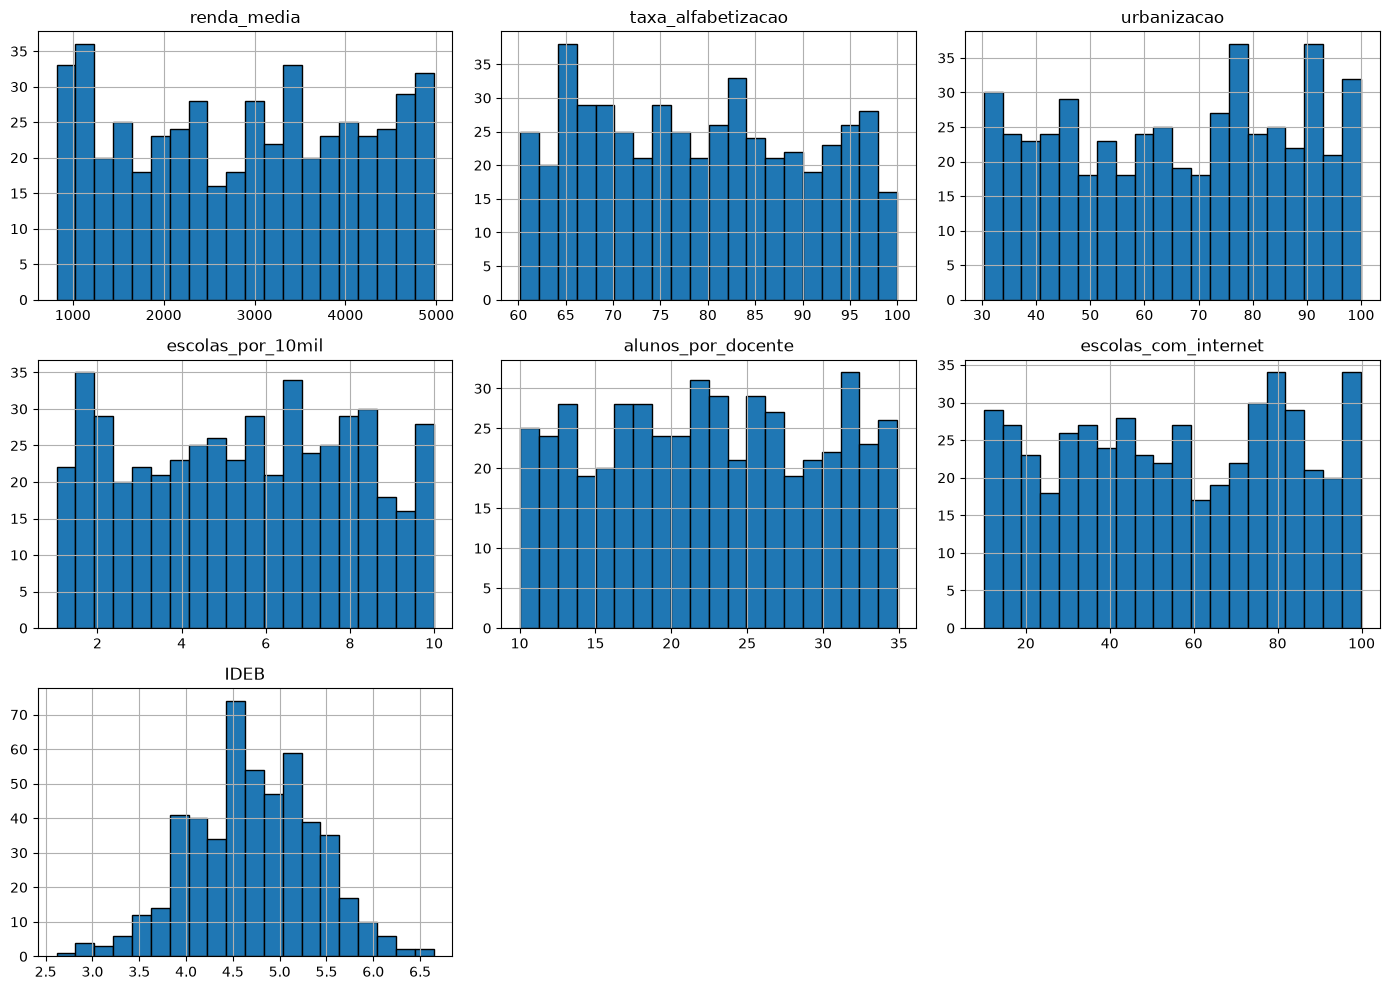

In [28]:
dataset.hist(
    figsize=(14, 10),
    bins=20,
    edgecolor="black"
)

plt.tight_layout()
plt.show()

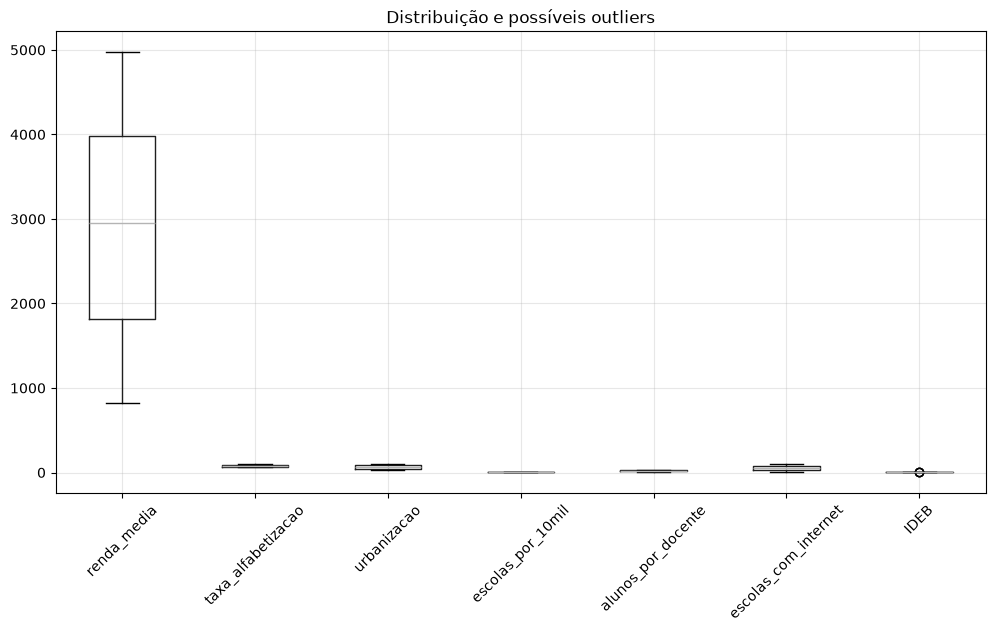

In [29]:
plt.figure(figsize=(12, 6))

dataset.boxplot()

plt.title("Distribuição e possíveis outliers")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.show()

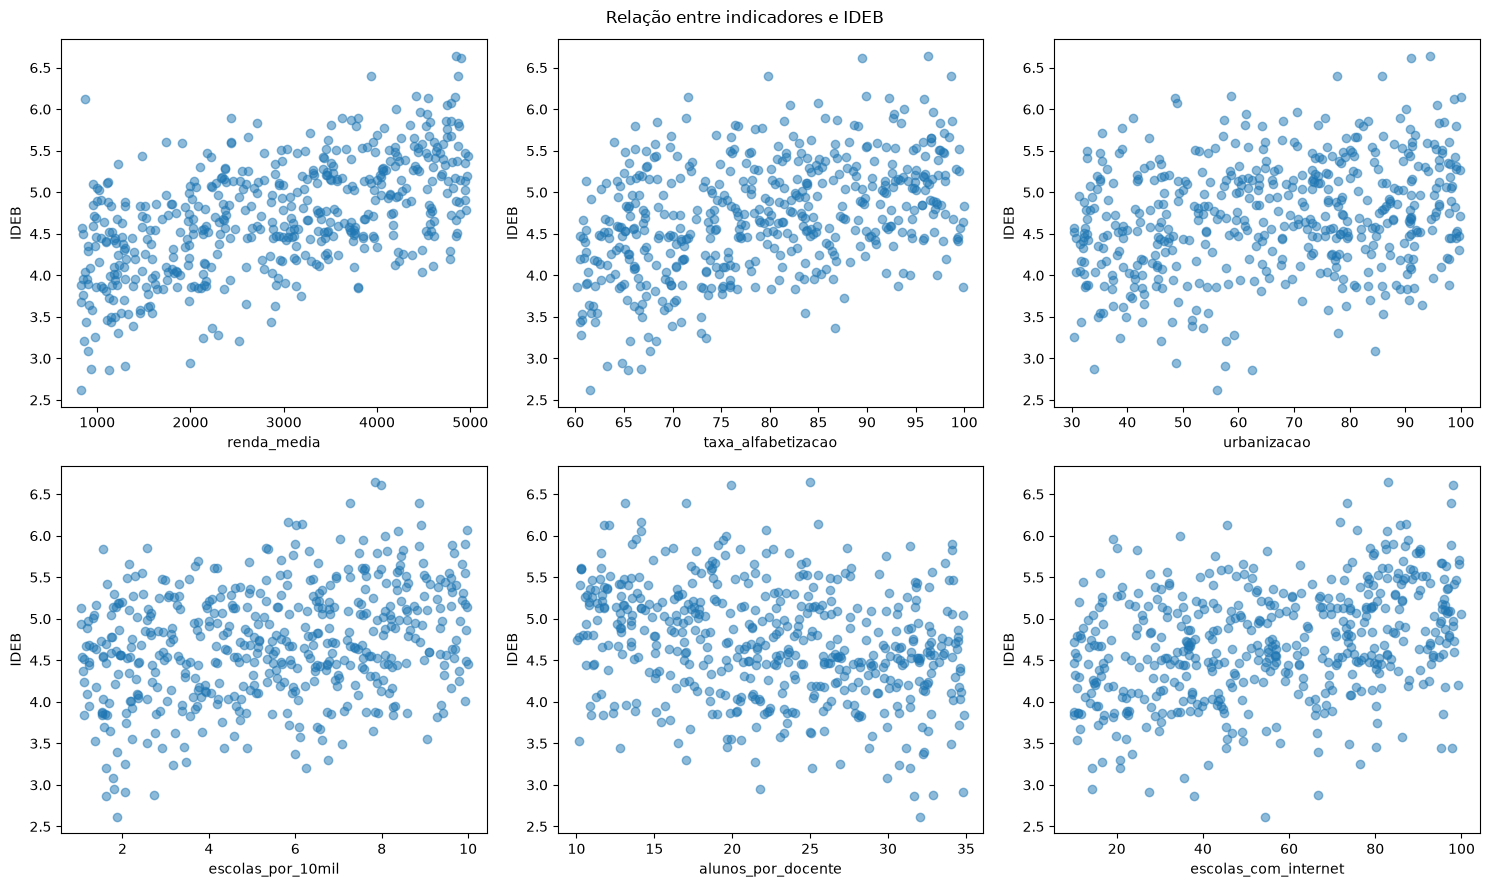

In [30]:
features = X.columns

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for feature, ax in zip(features, axes.flatten()):
    ax.scatter(dataset[feature], Y, alpha=0.5)

    ax.set_xlabel(feature)
    ax.set_ylabel("IDEB")

plt.suptitle("Relação entre indicadores e IDEB")
plt.tight_layout()
plt.show()